# 50 Identifying EV, heat pump and solar customers

Avangrid gave us lists of customers with three technologies: electric vehicles (**EV**), heat pumps (**HP**) and solar
panels (**PV**). The EV and HP lists are **random samples of about 25%** of the customers believed to have them, so
most EV and HP customers in the data are unlabeled. The PV list is described as complete. The goal is to score every
customer for each technology from their electricity use, and to estimate how many unlisted customers have each one.

**This is the only notebook with long-running models: a full run takes about 2 hours.** Everything it produces is
saved (DuckDB table `technology_predictions`, `onedrive-export/Data/eda/technology_candidates.csv` and the
comparison tables in `onedrive-export/Data/results/`), so the later notebooks only read the results.

### Why this needs a special approach

A normal classifier learns from examples of both classes: customers who *do* and who *don't* have an EV. We only have
the first kind. Every other customer is **unlabeled**: some have an EV, most don't, and we don't know which. This is
called **positive–unlabeled (PU) learning**. Two facts make it workable here:

1. The labeled customers were chosen **at random** from all customers with the technology, so labeled positives look
   like a typical positive.
2. We know roughly **what share** were labeled (about 25%), which turns model scores into probabilities and lets us
   estimate how many customers have each technology.

### How the notebook is organised

EV, HP and PV are handled **side by side** in every step, so the three can be compared directly.

| Part | What it does |
|---|---|
| **1. Method test on PV** | PV's full list gives a known answer: hide 75% of it and check which PU method finds the hidden customers best |
| **Round 1** | Notebook 40's features against added peer-relative and mid-year change features; tune the model settings; feature importance; first scores |
| **Round 2** | Add the signature features (solar index, charging blocks, cold-response shape) |
| **Round 3** | Add the peak-load features |
| **Round 4** | EV and HP: add appliance-rule evidence; check that the EV model responds to charging, not just home size |
| **Round 5** | HP: heat-pump physics features. EV: a night-by-night charging model and an ensemble |
| **Final scores** | `technology_predictions`, Elkan–Noto count estimates and the candidate lists |

Each round keeps a change only if it improves the **hidden-label AUC**: listed customers are hidden among the
unlabeled ones, and the AUC measures how well the model ranks them above customers on no list (1.0 is perfect, 0.5 is
random). EV and HP use 5-fold cross-validation over their lists; PV keeps a random 25% of its list labeled, to mimic
the EV and HP lists. Everything rejected along the way is summarised in the last section.

Run from the project folder after notebooks 10–45.

## Setup

`OMP_NUM_THREADS` is set to 1 before scikit-learn is imported. scikit-learn's gradient boosting otherwise starts one
thread per core for every small model, and with the hundreds of models fitted here those threads fight each other: a
run that takes about a minute single-threaded can take more than ten. Speed comes instead from fitting several models
at once in separate processes (`avangrid.pu`). Every model uses a fixed random seed, so results are the same on every
run.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # must be set before importing scikit-learn

import time
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import QuantileTransformer

import avangrid  # noqa: F401
from avangrid import (appliances, cache, config, customer_features as cfm, db, ev_nights, features, grids, physics,
                      pu, signatures, stability, weather)

warnings.filterwarnings('ignore', category=RuntimeWarning)  # ratios of zero-use hours; those features become NaN

DB_PATH = 'onedrive-export/Data/avangrid.db'
CUSTOMER_GROUPS_PATH = 'onedrive-export/Data/EV_Heat Pump_Solar PV Customers.xlsx'
PLOT_DIR = 'onedrive-export/Data/eda'
T0 = time.time()


def log(msg):
    print(f'[{time.time() - T0:5.0f}s] {msg}', flush=True)

# Part 1: Choosing the method, tested on PV

The PV list is the *full* list of solar customers, so for PV the right answer is known. Hiding 75% of the PV labels
mimics the EV and HP situation, and shows how well each method finds customers it wasn't told about.

The test uses notebook 40's full-year features (`customer_features`) and the EV, HP and PV labels.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.execute('SET enable_progress_bar = false')
features = con.sql('SELECT * FROM customer_features').pl()
FEATURE_COLS = [c for c in features.columns if c != 'CUSTOMER_NUMBER']

sheets = pl.read_excel(CUSTOMER_GROUPS_PATH, sheet_id=0)
sheets.pop('Description')
TECHS = ['EV', 'HP', 'PV']
for tab, customers in sheets.items():
    tech = tab.split()[0]
    features = features.with_columns(
        pl.col('CUSTOMER_NUMBER').is_in(customers['CUSTOMER_NUMBER'].cast(pl.Int32).implode()).alias(tech)
    )
print(f'{features.height:,} customers x {len(FEATURE_COLS)} features')
features.select([pl.col(t).sum() for t in TECHS])

33,566 customers x 23 features


EV,HP,PV
u32,u32,u32
179,86,389


## PU methods

We compare three ways of ranking unlabeled customers by how likely they are to have a technology. All three use only the labeled positives and the unlabeled customers, never confirmed negatives.

**1. Single-feature rule (baseline).** Rank customers by one hand-picked feature. For PV this is `summer_midday_night_ratio`, with lower meaning more solar-like. A model needs to beat this to be worth its complexity.

**2. Elkan–Noto (logistic regression).** Train an ordinary classifier to separate *labeled* from *unlabeled* customers. Because labeled customers are a random sample of the positives, its predicted probability equals c × P(has the technology), where c is the share of positives that are labeled. Dividing by c turns scores into **probabilities of having the technology**, and adding those up estimates **how many** customers have it.

c is estimated as the model's average score on labeled customers, using cross-validated (out-of-fold) predictions. For the PV test we also know the true c, 0.25, so we can see how good the estimate is. Logistic regression is used because its probabilities are generally well calibrated, which this method depends on. Features are first mapped to a normal distribution (`QuantileTransformer`) because many are heavily skewed.

**3. Bagging PU (gradient boosting).** Train many classifiers, each on all labeled positives plus a different **random sample** of unlabeled customers treated as negatives. Each unlabeled customer is scored only by the models that didn't use it in training, and those scores are averaged. A few hidden positives in each sample only mislead each model slightly, and averaging over many samples smooths that out. Gradient boosting can pick up non-linear patterns and interactions that logistic regression can't. The scores are rankings, not probabilities.

In [3]:
def as_matrix(df: pl.DataFrame) -> np.ndarray:
    X = df.select(FEATURE_COLS).to_numpy().astype(float)
    X[~np.isfinite(X)] = np.nan
    return X


def elkan_noto(X: np.ndarray, labeled: np.ndarray, seed: int):
    """Return (probability of being positive, estimated c, labeled-vs-unlabeled score g)."""
    model = make_pipeline(
        SimpleImputer(strategy='median'),
        QuantileTransformer(output_distribution='normal', random_state=seed),
        LogisticRegression(max_iter=3000),
    )
    g = cross_val_predict(
        model, X, labeled, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method='predict_proba'
    )[:, 1]
    c = g[labeled == 1].mean()
    return np.clip(g / c, 0, 1), c, g


def bagging_pu(X: np.ndarray, labeled: np.ndarray, seed: int, n_models: int = 30, neg_ratio: int = 10):
    """Average out-of-bag score for each unlabeled customer (NaN for labeled customers)."""
    rng = np.random.default_rng(seed)
    pos, unl = np.where(labeled == 1)[0], np.where(labeled == 0)[0]
    k = min(len(unl), neg_ratio * len(pos))
    total, count = np.zeros(len(labeled)), np.zeros(len(labeled))
    for b in range(n_models):
        sample = rng.choice(unl, k, replace=False)
        idx = np.r_[pos, sample]
        y = np.r_[np.ones(len(pos)), np.zeros(k)]
        model = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=seed * 1000 + b)
        model.fit(X[idx], y)
        out_of_bag = np.setdiff1d(unl, sample)
        total[out_of_bag] += model.predict_proba(X[out_of_bag])[:, 1]
        count[out_of_bag] += 1
    return np.where(count > 0, total / np.maximum(count, 1), np.nan)

## Test on PV: hide 75% of the labels

To mimic the EV and HP situation, each run keeps a **random 25%** of PV customers labeled and treats the other 75% as unlabeled. We then check how well each method finds the hidden PV customers among all the unlabeled ones. The run is repeated 10 times with different random 25% samples, to show how stable the results are.

**Metrics**, calculated on the unlabeled customers only:

- **AUC**: the chance that a randomly chosen hidden PV customer is ranked above a randomly chosen non-PV customer. 1.0 is perfect; 0.5 is random guessing.
- **Precision in the top k**: k is set to the number of hidden PV customers. Of the k highest-ranked customers, this is the share that really are on the PV list. It's the most practical measure: "if we flagged as many customers as there are hidden PV customers, how many would be right?"
- **Estimated total PV** (Elkan–Noto only): the sum of predicted probabilities, using either the estimated c or the known c = 0.25, compared with the true count.

**Caveat:** if the PV list is not actually complete (see the next section), some top-ranked "non-PV" customers may really have solar. In that case these figures *understate* how well the methods work.

This cell takes about 2 minutes.

In [4]:
X = as_matrix(features)
is_pv = features['PV'].to_numpy()
pv_positions = np.where(is_pv)[0]
rule_score = -features['summer_midday_night_ratio'].fill_null(1.0).to_numpy()  # lower ratio = more solar-like

N_REPEATS = 10
LABELED_SHARE = 0.25
results = []

for seed in range(N_REPEATS):
    rng = np.random.default_rng(100 + seed)
    labeled = np.zeros(len(is_pv), dtype=int)
    labeled[rng.choice(pv_positions, round(LABELED_SHARE * len(pv_positions)), replace=False)] = 1

    unlabeled = labeled == 0
    hidden_pv = is_pv[unlabeled]
    k = hidden_pv.sum()

    p_en, c_est, g = elkan_noto(X, labeled, seed)
    p_bag = bagging_pu(X, labeled, seed)

    for method, score in [('Rule: summer midday/night ratio', rule_score),
                          ('Elkan–Noto (logistic regression)', p_en),
                          ('Bagging PU (gradient boosting)', p_bag)]:
        s = score[unlabeled]
        top_k = np.argsort(-s)[:k]
        results.append({
            'repeat': seed,
            'method': method,
            'auc': roc_auc_score(hidden_pv, s),
            'precision_top_k': hidden_pv[top_k].mean(),
            'estimated_c': c_est if method.startswith('Elkan') else None,
            'est_total_estimated_c': p_en.sum() if method.startswith('Elkan') else None,
            'est_total_known_c': np.clip(g / LABELED_SHARE, 0, 1).sum() if method.startswith('Elkan') else None,
        })

results = pl.DataFrame(results)
pv_test_summary = (
    results.group_by('method', maintain_order=True)
    .agg(
        pl.col('auc').mean().round(3).alias('auc_mean'),
        pl.col('auc').std().round(3).alias('auc_sd'),
        pl.col('precision_top_k').mean().round(3).alias('precision_top_k_mean'),
        pl.col('precision_top_k').std().round(3).alias('precision_top_k_sd'),
        pl.col('estimated_c').mean().round(3),
        pl.col('est_total_estimated_c').mean().round(0),
        pl.col('est_total_known_c').mean().round(0),
    )
)
print(f'True PV customers in the analysis data: {is_pv.sum()}; '
      f'labeled in each run: {round(LABELED_SHARE * len(pv_positions))}; hidden: {is_pv.sum() - round(LABELED_SHARE * len(pv_positions))}')
with pl.Config(tbl_cols=-1, tbl_hide_dataframe_shape=True):
    print(pv_test_summary)

True PV customers in the analysis data: 389; labeled in each run: 97; hidden: 292
┌─────────────┬──────────┬────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ method      ┆ auc_mean ┆ auc_sd ┆ precision_ ┆ precision_ ┆ estimated_ ┆ est_total_ ┆ est_total_ │
│ ---         ┆ ---      ┆ ---    ┆ top_k_mean ┆ top_k_sd   ┆ c          ┆ estimated_ ┆ known_c    │
│ str         ┆ f64      ┆ f64    ┆ ---        ┆ ---        ┆ ---        ┆ c          ┆ ---        │
│             ┆          ┆        ┆ f64        ┆ f64        ┆ f64        ┆ ---        ┆ f64        │
│             ┆          ┆        ┆            ┆            ┆            ┆ f64        ┆            │
╞═════════════╪══════════╪════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ Rule:       ┆ 0.944    ┆ 0.005  ┆ 0.667      ┆ 0.005      ┆ null       ┆ null       ┆ null       │
│ summer midd ┆          ┆        ┆            ┆            ┆            ┆            ┆            │
│ ay/nigh

### What the PV test shows

- **Both PU models beat the single-feature rule.** Combining many features finds more hidden solar customers than the best single feature: precision in the top k rises from about 0.67 to 0.80–0.85.
- **Bagging PU is the better ranker.** Its AUC is about the same as Elkan–Noto's, but it puts more true PV customers at the very top of the list (higher precision in the top k), which is what matters when flagging customers. The results barely change between runs (small standard deviations), so they don't hinge on which 25% happened to be labeled.
- **Elkan–Noto's count estimates bracket the truth.** Its estimated c (about 0.16) is lower than the true 0.25, so the total comes out about 21% too high (about 471 vs 389). Using the known c = 0.25 gives a total about 12% too low (about 343). The model's probabilities aren't perfectly calibrated, so neither estimate is exact. For EV and HP, the two together give a **plausible range** rather than a single number.

Overall, the approach works: with only a quarter of solar customers labeled, the models recover most of the rest at high precision. That supports applying the same pipeline to EV and HP, using **bagging PU for ranking** and **Elkan–Noto (estimated and known c) for a range of how many there are**.

## Is the PV list really complete?

About 1,000 customers *not* on the PV list have near-zero use in at least 30% of summer midday hours (counted below). That could mean unlisted solar, or homes that are empty or used seasonally.

To check, we train bagging PU on **all** PV labels and score every customer not on the list. A high score means "looks like the PV customers". We then compare these groups:

- **PV list**: all labeled solar customers;
- **Off-list, solar-like**: not on the list, score of at least 0.5;
- **Off-list, low midday use, not solar-like**: near-zero use in at least 30% of summer midday hours, but scoring below 0.5;
- **Everyone else**.

In [5]:
pv_labeled = is_pv.astype(int)
pv_score = bagging_pu(X, pv_labeled, seed=0)
features = features.with_columns(pl.Series('pv_score', pv_score))

off_list = features.filter(~pl.col('PV'))
low_midday = pl.col('summer_midday_zero_share') >= 0.30
print('Off-list customers scoring at least ...')
for t in [0.3, 0.5, 0.7, 0.9]:
    print(f'  {t}: {off_list.filter(pl.col("pv_score") >= t).height}')

lm = off_list.filter(low_midday)
print(f'\nOff-list with near-zero use in >= 30% of summer midday hours: {lm.height}')
print(f'  of which also use < 0.1 kWh at summer night (likely empty or seasonal): '
      f'{lm.filter(pl.col("summer_night_kwh") < 0.1).height}')
print(f'  of which score >= 0.5 (solar-like): {lm.filter(pl.col("pv_score") >= 0.5).height}')

features = features.with_columns(
    pl.when(pl.col('PV')).then(pl.lit('PV list'))
    .when(pl.col('pv_score') >= 0.5).then(pl.lit('Off-list, solar-like (score ≥ 0.5)'))
    .when(low_midday).then(pl.lit('Off-list, low midday use, not solar-like'))
    .otherwise(pl.lit('Everyone else'))
    .alias('pv_check_group')
)
features.group_by('pv_check_group').agg(
    pl.len().alias('customers'),
    pl.col('summer_midday_kwh').median().round(3),
    pl.col('summer_night_kwh').median().round(3),
    pl.col('summer_midday_night_ratio').median().round(3),
    pl.col('midday_summer_winter_ratio').median().round(3),
).sort('customers')

Off-list customers scoring at least ...
  0.3: 126
  0.5: 85
  0.7: 55
  0.9: 32

Off-list with near-zero use in >= 30% of summer midday hours: 1029
  of which also use < 0.1 kWh at summer night (likely empty or seasonal): 557
  of which score >= 0.5 (solar-like): 59


pv_check_group,customers,summer_midday_kwh,summer_night_kwh,summer_midday_night_ratio,midday_summer_winter_ratio
str,u32,f64,f64,f64,f64
"""Off-list, solar-like (score ≥ …",85,0.366,0.665,0.461,0.422
"""PV list""",389,0.201,0.837,0.244,0.243
"""Off-list, low midday use, not …",970,0.083,0.082,1.041,0.5
"""Everyone else""",32122,0.786,0.557,1.35,0.99


### Average summer day for each group

The clearest check is to look at the average summer day. The chart shows average use for each hour of the day, Apr–Sep, for each group. Solar homes should dip sharply around midday while using normal amounts in the evening and at night. Empty or seasonal homes should be low all day.

The profiles are calculated in DuckDB over `ami_analysis`.

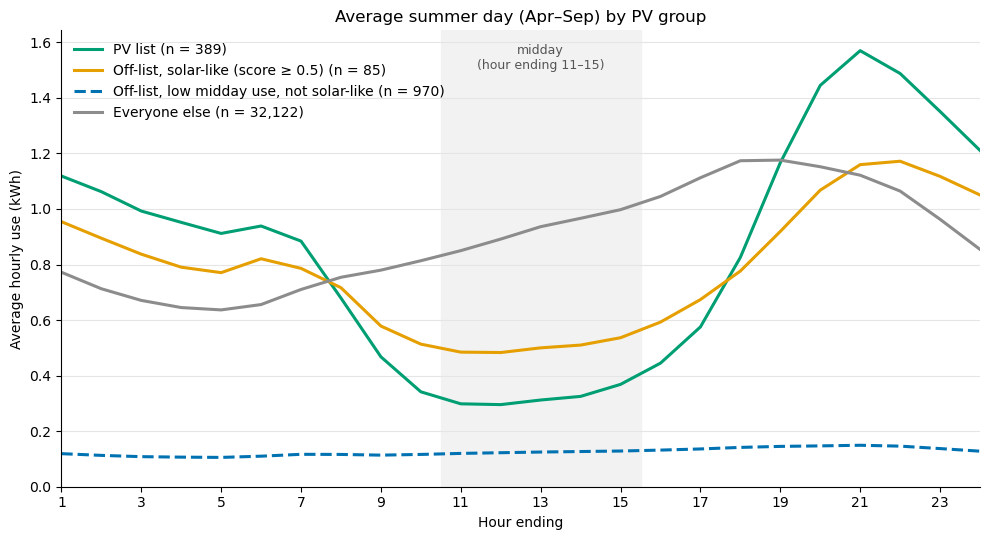

In [6]:
con.register('pv_check_groups', features.select('CUSTOMER_NUMBER', 'pv_check_group'))
profiles = con.sql('''
    SELECT g.pv_check_group, a.hour_ending, AVG(a.hourly_kwh) AS avg_kwh
    FROM ami_analysis a JOIN pv_check_groups g USING (CUSTOMER_NUMBER)
    WHERE month(a.usage_date) BETWEEN 4 AND 9
    GROUP BY ALL ORDER BY ALL
''').pl()

GROUP_STYLE = {
    'PV list': ('#009E73', '-'),
    'Off-list, solar-like (score ≥ 0.5)': ('#E69F00', '-'),
    'Off-list, low midday use, not solar-like': ('#0072B2', '--'),
    'Everyone else': ('#8c8c8c', '-'),
}
counts = dict(features.group_by('pv_check_group').len().iter_rows())

fig, ax = plt.subplots(figsize=(10, 5.5))
for group, (color, style) in GROUP_STYLE.items():
    p = profiles.filter(pl.col('pv_check_group') == group)
    ax.plot(p['hour_ending'], p['avg_kwh'], color=color, linestyle=style, linewidth=2.2,
            label=f'{group} (n = {counts[group]:,})')

ax.axvspan(10.5, 15.5, color='#f2f2f2', zorder=0)
ax.text(13, ax.get_ylim()[1] * 0.97, 'midday\n(hour ending 11–15)', ha='center', va='top', fontsize=9, color='#555555')
ax.set_xticks(range(1, 25, 2))
ax.set_xlim(1, 24)
ax.set_ylim(bottom=0)
ax.set_xlabel('Hour ending')
ax.set_ylabel('Average hourly use (kWh)')
ax.set_title('Average summer day (Apr–Sep) by PV group')
ax.grid(axis='y', color='#e5e5e5', linewidth=0.8)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper left')
fig.tight_layout()
fig.savefig(f'{PLOT_DIR}/pv_check_summer_profiles.png', dpi=150)
plt.show()

### What this means for the PV list

- Most off-list customers with low midday use are **not** solar. They use little all day, including at night, which suggests empty, seasonal or very low-use homes. The model correctly scores them low, so the features separate "no one home" from "panels generating".
- A smaller group of off-list customers **does** look like solar: a deep midday dip with normal evening use, scoring highly against the PV customers. These may be **unlisted solar customers**, for example installations that are new, not registered, or missed when the list was put together. They're worth raising with Avangrid. Until that's resolved, PV labels should be treated as *nearly* complete rather than perfect.

The candidates are saved below for follow-up.

In [7]:
PV_CANDIDATES_PATH = f'{PLOT_DIR}/pv_offlist_candidates.csv'
pv_candidates = (
    features.filter(pl.col('pv_check_group') == 'Off-list, solar-like (score ≥ 0.5)')
    .select('CUSTOMER_NUMBER', 'pv_score', 'summer_midday_kwh', 'summer_night_kwh',
            'summer_midday_night_ratio', 'midday_summer_winter_ratio', 'summer_midday_zero_share', 'EV', 'HP')
    .sort('pv_score', descending=True)
)
pv_candidates.write_csv(PV_CANDIDATES_PATH)
print(f'Saved {pv_candidates.height} off-list PV candidates to {PV_CANDIDATES_PATH}')
pv_candidates.head(10)

Saved 85 off-list PV candidates to onedrive-export/Data/eda/pv_offlist_candidates.csv


CUSTOMER_NUMBER,pv_score,summer_midday_kwh,summer_night_kwh,summer_midday_night_ratio,midday_summer_winter_ratio,summer_midday_zero_share,EV,HP
i32,f64,f64,f64,f64,f64,f64,bool,bool
30356,0.999923,0.243603,0.83805,0.290678,0.188466,0.567213,false,false
33439,0.999923,0.385215,1.565909,0.246001,0.375181,0.612022,false,false
32034,0.999906,0.027541,0.872357,0.031571,0.123118,0.919126,false,false
29211,0.999859,0.022819,0.467451,0.048815,0.090783,0.889617,false,false
17885,0.999847,0.436804,1.410151,0.309757,0.219791,0.402186,false,false
12940,0.999833,0.16934,0.679311,0.249282,0.237854,0.704918,false,false
33035,0.999823,0.149109,1.258686,0.118464,0.240192,0.808743,false,false
29200,0.999803,0.183096,1.374036,0.133254,0.138452,0.784699,false,false
32347,0.99965,0.559889,1.634733,0.342495,0.565672,0.356284,false,false


In [8]:
con.close()  # the avangrid package opens its own connections from here on
del features
from avangrid import features  # noqa: E402  (the name was used for the table above)

# From one method to three models

The PV test supports the pipeline used from here on: **rank** customers with **bagging PU**, and **estimate how many**
have each technology with **Elkan–Noto**, reporting totals from both the estimated c and the known c ≈ 0.25 for EV and
HP. Two things to keep in mind: the EV and HP lists are customers Avangrid *believes* have the technology, so some
labels may be wrong; and other heavy loads (electric resistance heating, pool or well pumps, large homes) can look
like EV or HP. Features based on the *shape* of use, not its size, help guard against that (round 4 tests this).

From here on the models use the `avangrid` package: the same bagging PU, run in parallel processes, on the cached
customers × days × 24 arrays from notebook 40 (customers in the peer groups).

## Shared data and feature blocks

- **A**: notebook 40's full-year features.
- **B**: peer-relative features over the full year (`features.PeriodFeatures`), plus log average use.
- **Z**: each technology's mid-year change score and flag (notebook 45's technology-specific scans, rebuilt by
  `stability.tech_change_points` with the stabilization length saved in notebook 45).
- **C**: the same peer-relative features measured only since a technology's flagged change, the before/after
  differences, and the length of that current period (built per technology).

In [9]:
hd = grids.load_hourly(verbose=False)
D, _ = features.load_daily_signals(hd, verbose=False)
pf = features.PeriodFeatures(D, hd.temp)
n, n_days = hd.shape[0], hd.shape[1]
labels = hd.labels()
not_listed = ~(labels['EV'] | labels['HP'] | labels['PV'])
min_weeks = int(np.ceil(db.sql('SELECT ANY_VALUE(stabilization_days) AS d FROM customer_stability')['d'].item() / 7))

A, A_names = features.customer_features(hd.customer_numbers)
log_mean = np.log(hd.customers['mean_kwh_real'].to_numpy())
B, B_names = pf.to_matrix(pf(0, n_days), {'log_mean_kwh': log_mean})
B_names = [f'peer_{k}' for k in B_names]

cp = stability.tech_change_points(D, hd.kwh, hd.temp, min_weeks, not_listed)
Z = np.column_stack([cp[t]['z'] for t in config.TECHS] + [cp[t]['flag'].astype(float) for t in config.TECHS])
Z_names = [f'{t.lower()}_change_z' for t in config.TECHS] + [f'{t.lower()}_change_flag' for t in config.TECHS]


def current_period_block(tech):
    """Current-period features since this technology's flagged change, the before/after differences, period length."""
    flag = cp[tech]['flag']
    change_day = np.where(flag, cp[tech]['week'] * 7, 0)
    cur, bef = pf(change_day, n_days), pf(0, np.maximum(change_day, 1))
    names = list(cur)
    X = np.column_stack([cur[k] for k in names] + [np.where(flag, cur[k] - bef[k], 0) for k in names]
                        + [(n_days - change_day) / 7])
    X[~np.isfinite(X)] = np.nan
    return X, [f'current_{k}' for k in names] + [f'change_in_{k}' for k in names] + ['current_period_weeks']


def build_sets(tech):
    C, C_names = current_period_block(tech)
    return {
        'A: notebook 40': (A, A_names),
        'A+B: + peer-relative': (np.hstack([A, B]), A_names + B_names),
        'A+B+Z: + change scores': (np.hstack([A, B, Z]), A_names + B_names + Z_names),
        'A+B+Z+C: + current period': (np.hstack([A, B, Z, C]), A_names + B_names + Z_names + C_names),
    }


SCHEME = {'PV': 'hide', 'EV': 'kfold', 'HP': 'kfold'}   # PV: keep 25% labeled; EV/HP: 5-fold over the listed

# Round 1: Which features, and which model settings?

## Stage 1: feature sets

Four nested sets per technology: A, A+B, A+B+Z, and A+B+Z+C. The set with the highest mean AUC is kept.

In [10]:
# ---------------------------------------------------------------- 1. feature sets
log('Stage 1: feature-set comparison')
stage1 = []
sets_by_tech = {}
for tech in config.TECHS:
    sets_by_tech[tech] = build_sets(tech)
    res = pu.evaluate_feature_sets({k: v[0] for k, v in sets_by_tech[tech].items()}, labels[tech],
                                   scheme=SCHEME[tech], n_splits=5, verbose=False)
    stage1.append(res.with_columns(pl.lit(tech).alias('technology')))
    log(f'  {tech} done')
stage1 = pl.concat(stage1)
cache.save_results('predict_stage1_feature_sets', stage1)

summary1 = stage1.group_by('technology', 'feature_set', maintain_order=True).agg(
    pl.col('auc').mean().alias('auc'), pl.col('auc').std().alias('auc_sd'),
    pl.col('precision_top_k').mean().alias('precision_top_k'))
best_set = {t: summary1.filter(pl.col('technology') == t).sort('auc', descending=True)['feature_set'][0]
            for t in config.TECHS}
log(f'Best feature sets: {best_set}')

[  165s] Stage 1: feature-set comparison


[  200s]   EV done


[  227s]   HP done


[  255s]   PV done


[  255s] Best feature sets: {'EV': 'A: notebook 40', 'HP': 'A+B+Z+C: + current period', 'PV': 'A+B+Z+C: + current period'}


In [11]:
summary1.sort('technology', 'auc', descending=[False, True])

technology,feature_set,auc,auc_sd,precision_top_k
str,str,f64,f64,f64
"""EV""","""A: notebook 40""",0.752831,0.036918,0.016667
"""EV""","""A+B+Z: + change scores""",0.750127,0.052996,0.038889
"""EV""","""A+B: + peer-relative""",0.744019,0.04726,0.039048
"""EV""","""A+B+Z+C: + current period""",0.743116,0.052667,0.039048
"""HP""","""A+B+Z+C: + current period""",0.755737,0.058835,0.0
…,…,…,…,…
"""HP""","""A+B: + peer-relative""",0.74606,0.059767,0.0
"""PV""","""A+B+Z+C: + current period""",0.971541,0.007043,0.842466
"""PV""","""A+B+Z: + change scores""",0.971528,0.006851,0.844521


## Stage 2: bagging settings

With each technology's best set, five settings of the bagging PU model: the default (10 unlabeled customers sampled
per labeled one, 200-tree gradient boosting, 20 models), 5:1 and 20:1 sampling, regularized trees, and 50 models.

In [12]:
# ---------------------------------------------------------------- 2. model settings
log('Stage 2: tuning bagging settings')
CONFIGS = {
    'default (10:1, 200 trees)': {},
    '5:1 sampling': {'neg_ratio': 5},
    '20:1 sampling': {'neg_ratio': 20},
    'regularized trees': {'model_params': {'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'l2_regularization': 1.0}},
    '50 models': {'n_models': 50},
}
stage2 = []
for tech in config.TECHS:
    X = sets_by_tech[tech][best_set[tech]][0]
    for name, kw in CONFIGS.items():
        res = pu.evaluate_feature_sets({best_set[tech]: X}, labels[tech], scheme=SCHEME[tech], n_splits=5,
                                       verbose=False, **kw)
        stage2.append(res.with_columns(pl.lit(tech).alias('technology'), pl.lit(name).alias('config')))
    log(f'  {tech} done')
stage2 = pl.concat(stage2)
cache.save_results('predict_stage2_configs', stage2)
summary2 = stage2.group_by('technology', 'config', maintain_order=True).agg(
    pl.col('auc').mean().alias('auc'), pl.col('auc').std().alias('auc_sd'),
    pl.col('precision_top_k').mean().alias('precision_top_k'))
best_cfg = {t: summary2.filter(pl.col('technology') == t).sort('auc', descending=True)['config'][0]
            for t in config.TECHS}
log(f'Best settings: {best_cfg}')

[  255s] Stage 2: tuning bagging settings


[  294s]   EV done


[  337s]   HP done


[  384s]   PV done


[  384s] Best settings: {'EV': '50 models', 'HP': '5:1 sampling', 'PV': '50 models'}


In [13]:
summary2.sort('technology', 'auc', descending=[False, True])

technology,config,auc,auc_sd,precision_top_k
str,str,f64,f64,f64
"""EV""","""50 models""",0.753844,0.039303,0.016667
"""EV""","""default (10:1, 200 trees)""",0.752831,0.036918,0.016667
"""EV""","""5:1 sampling""",0.751466,0.045521,0.02254
"""EV""","""20:1 sampling""",0.750814,0.035311,0.039048
"""EV""","""regularized trees""",0.750629,0.042101,0.016825
…,…,…,…,…
"""PV""","""50 models""",0.971557,0.006916,0.844521
"""PV""","""default (10:1, 200 trees)""",0.971541,0.007043,0.842466
"""PV""","""5:1 sampling""",0.971382,0.006266,0.845205


## Stage 3: permutation importance

How much the hidden-label AUC drops when one feature, or one family of features, is shuffled. Computed on three
hidden-label splits, for single features and for feature families.

In [14]:
# ---------------------------------------------------------------- 3. feature importance
def family(name):
    base = name.removeprefix('peer_').removeprefix('current_').removeprefix('change_in_')
    if name.endswith('_change_z') or name.endswith('_change_flag') or name == 'current_period_weeks':
        return 'Mid-year change scores'
    if name.startswith('change_in_'):
        return 'Change in features since flagged change'
    if name.startswith('current_'):
        return 'Current-period features'
    if any(s in base for s in ['midday', 'zero', 'dip', 'summer_night', 'midday_summer_winter']):
        return 'Solar / midday signature'
    if any(s in base for s in ['high_', 'session', 'sharp_rise']):
        return 'EV / high-power signature'
    if any(s in base for s in ['heat', 'cold', 'winter', 'cool']):
        return 'Heating & cooling response'
    if any(s in base for s in ['mean_kwh', 'p95', 'max_kwh', 'mild_day', 'log_mean', 'e_level']):
        return 'Size / overall level'
    return 'Daily shape (time of day)'


log('Stage 3: permutation importance')
importance = []
for tech in config.TECHS:
    X, names = sets_by_tech[tech][best_set[tech]]
    kw = CONFIGS[best_cfg[tech]]
    fam = {}
    for nm in names:
        fam.setdefault(family(nm), []).append(nm)
    for split, labeled in pu.hidden_label_splits(labels[tech], SCHEME[tech], n_splits=3):
        models = pu.fit_bagging_models(X, labeled, seed=split, **{k: v for k, v in kw.items()})
        hidden = labels[tech] & ~labeled
        rows = np.flatnonzero(hidden | ~labels[tech])
        y = hidden[rows]
        for kind, groups in [('feature', None), ('family', fam)]:
            imp = pu.permutation_importance(models, X, rows, y, names, n_repeats=2, seed=split, groups=groups)
            importance.append(imp.with_columns(pl.lit(tech).alias('technology'), pl.lit(kind).alias('kind'),
                                               pl.lit(split).alias('split')))
    log(f'  {tech} done')
importance = pl.concat(importance, how='diagonal')
cache.save_results('predict_stage3_importance', importance)

[  384s] Stage 3: permutation importance


[  843s]   EV done


[ 1092s]   HP done


[ 1895s]   PV done


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/predict_stage3_importance.parquet')

## Stage 4: first scores for every customer

The final model for each technology is trained on all listed customers with at least 50 models. Unlabeled customers
get out-of-bag scores; listed customers get **out-of-fold** scores (from models that didn't see them), so their scores
are comparable. Elkan–Noto estimates how many customers have each technology.

In [15]:
# ---------------------------------------------------------------- 4. final models
log('Stage 4: final models')
out = hd.customers.select('CUSTOMER_NUMBER')
counts = []
for tech in config.TECHS:
    X, names = sets_by_tech[tech][best_set[tech]]
    kw = dict(CONFIGS[best_cfg[tech]])
    kw['n_models'] = max(kw.get('n_models', 20), 50)          # more models for the final ranking
    is_pos = labels[tech]
    final, _ = pu.bagging_pu(X, is_pos, seed=0, **kw)          # unlabeled customers: out-of-bag scores
    oof = np.full(n, np.nan)                                   # listed customers: out-of-fold scores
    for split, lab in pu.hidden_label_splits(is_pos, 'kfold', n_splits=5):
        s, _ = pu.bagging_pu(X, lab, seed=split, **kw)
        held = is_pos & ~lab
        oof[held] = s[held]
    score = np.where(is_pos, oof, final)
    pct = pl.Series(score).rank('average').to_numpy() / n
    out = out.with_columns(pl.Series(f'{tech.lower()}_score', score), pl.Series(f'{tech.lower()}_percentile', pct),
                           pl.Series(f'{tech.lower()}_listed', is_pos))

    p, c_est, g = pu.elkan_noto(X, is_pos, seed=0)
    est_total = float(p.sum())
    est_total_known = float(np.clip(g / 0.25, 0, 1).sum()) if tech in ('EV', 'HP') else None
    counts.append({'technology': tech, 'listed_in_analysis': int(is_pos.sum()), 'estimated_c': float(c_est),
                   'est_total_estimated_c': est_total, 'est_total_known_c_0.25': est_total_known,
                   'unlisted_score_ge_0.5': int(((final >= 0.5) & ~is_pos).sum()),
                   'unlisted_score_ge_0.7': int(((final >= 0.7) & ~is_pos).sum())})
    log(f'  {tech} done')
counts = pl.DataFrame(counts)
cache.save_results('predict_stage4_counts', counts)
cache.save_results('predict_stage4_scores', out)
cache.save_results('predict_meta', pl.DataFrame({'technology': list(config.TECHS),
                                                 'best_set': [best_set[t] for t in config.TECHS],
                                                 'best_config': [best_cfg[t] for t in config.TECHS]}))
log('All stages done')

[ 1895s] Stage 4: final models


[ 1914s]   EV done


[ 1930s]   HP done


[ 1961s]   PV done


[ 1961s] All stages done


In [16]:
counts

technology,listed_in_analysis,estimated_c,est_total_estimated_c,est_total_known_c_0.25,unlisted_score_ge_0.5,unlisted_score_ge_0.7
str,i64,f64,f64,f64,i64,i64
"""EV""",179,0.026564,5783.563364,714.905944,316,163
"""HP""",86,0.008219,8504.360543,344.41261,968,281
"""PV""",389,0.749253,446.936596,null,73,56


# Round 2: Signature features

Three groups of features designed for one technology each (`avangrid.signatures`):

- **Solar index** (PV): how closely a customer's midday dip tracks sunny days across all customers.
- **Charging blocks** (EV): blocks of several hours well above the customer's usual use, their size, length and timing.
- **Cold-response shape** (HP): how heating use responds in different temperature bands, defrost-like and backup-like
  behaviour.

Each technology's round-1 set is compared with: + its own signature group, + all signatures, and A + all signatures.

In [17]:
sig = signatures.load_signatures(hd, D, verbose=False)
S_GROUP = {'PV': 'Solar index', 'EV': 'Charging blocks', 'HP': 'Cold-response shape'}
S_all, S_all_names = signatures.to_matrix(sig)
meta = cache.load_results('predict_meta')
best_set = dict(zip(meta['technology'], meta['best_set']))
best_cfg = dict(zip(meta['technology'], meta['best_config']))
CONFIGS = {
    'default (10:1, 200 trees)': {},
    '5:1 sampling': {'neg_ratio': 5},
    '20:1 sampling': {'neg_ratio': 20},
    'regularized trees': {'model_params': {'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'l2_regularization': 1.0}},
    '50 models': {'n_models': 50},
}

In [18]:
# ---------------------------------------------------------------- 5. new signature features
log('Stage 5: testing signature features')
stage5, cand = [], {}
for tech in config.TECHS:
    base_X, base_names = build_sets(tech)[best_set[tech]]
    S_t, S_t_names = signatures.to_matrix(sig, (S_GROUP[tech],))
    cand[tech] = {
        f'previous best ({best_set[tech]})': (base_X, base_names),
        f'previous best + {S_GROUP[tech]}': (np.hstack([base_X, S_t]), base_names + S_t_names),
        'previous best + all signatures': (np.hstack([base_X, S_all]), base_names + S_all_names),
        'A + all signatures': (np.hstack([A, S_all]), A_names + S_all_names),
    }
    res = pu.evaluate_feature_sets({k: v[0] for k, v in cand[tech].items()}, labels[tech], scheme=SCHEME[tech],
                                   n_splits=5, verbose=False, **CONFIGS[best_cfg[tech]])
    stage5.append(res.with_columns(pl.lit(tech).alias('technology')))
    log(f'  {tech} done')
stage5 = pl.concat(stage5)
cache.save_results('predict_stage5_signatures', stage5)
summary5 = stage5.group_by('technology', 'feature_set', maintain_order=True).agg(pl.col('auc').mean().alias('auc'))
final_set = {t: summary5.filter(pl.col('technology') == t).sort('auc', descending=True)['feature_set'][0] for t in config.TECHS}
log(f'Best after adding signatures: {final_set}')

[ 1984s] Stage 5: testing signature features


[ 2048s]   EV done


[ 2070s]   HP done


[ 2140s]   PV done


[ 2140s] Best after adding signatures: {'EV': 'previous best (A: notebook 40)', 'HP': 'previous best + Cold-response shape', 'PV': 'previous best + all signatures'}


In [19]:
summary5.sort('technology', 'auc', descending=[False, True])

technology,feature_set,auc
str,str,f64
"""EV""","""previous best (A: notebook 40)""",0.753844
"""EV""","""previous best + Charging block…",0.740985
"""EV""","""previous best + all signatures""",0.739283
"""EV""","""A + all signatures""",0.739283
"""HP""","""previous best + Cold-response …",0.769532
…,…,…
"""HP""","""A + all signatures""",0.752783
"""PV""","""previous best + all signatures""",0.973207
"""PV""","""A + all signatures""",0.972773


## Stage 6: importance for the round-2 models

Feature families now include the three signature groups, marked "(new)".

In [20]:
def family(name):
    if name in signatures.GROUPS['Solar index']:
        return 'Solar index (new)'
    if name in signatures.GROUPS['Charging blocks']:
        return 'Charging blocks (new)'
    if name in signatures.GROUPS['Cold-response shape']:
        return 'Cold-response shape (new)'
    base = name.removeprefix('peer_').removeprefix('current_').removeprefix('change_in_')
    if name.endswith('_change_z') or name.endswith('_change_flag') or name == 'current_period_weeks':
        return 'Mid-year change scores'
    if name.startswith('change_in_'):
        return 'Change in features since flagged change'
    if name.startswith('current_'):
        return 'Current-period features'
    if any(s in base for s in ['midday', 'zero', 'dip', 'summer_night', 'midday_summer_winter']):
        return 'Solar / midday signature'
    if any(s in base for s in ['high_', 'session', 'sharp_rise']):
        return 'EV / high-power signature'
    if any(s in base for s in ['heat', 'cold', 'winter', 'cool']):
        return 'Heating & cooling response'
    if any(s in base for s in ['mean_kwh', 'p95', 'max_kwh', 'mild_day', 'log_mean', 'e_level']):
        return 'Size / overall level'
    return 'Daily shape (time of day)'



log('Stage 6: importance for the final models')
importance = []
for tech in config.TECHS:
    X, names = cand[tech][final_set[tech]]
    kw = CONFIGS[best_cfg[tech]]
    fam = {}
    for nm in names:
        fam.setdefault(family(nm), []).append(nm)
    for split, labeled in pu.hidden_label_splits(labels[tech], SCHEME[tech], n_splits=3):
        models = pu.fit_bagging_models(X, labeled, seed=split, **kw)
        hidden = labels[tech] & ~labeled
        rows = np.flatnonzero(hidden | ~labels[tech])
        y = hidden[rows]
        for kind, groups in [('feature', None), ('family', fam)]:
            imp = pu.permutation_importance(models, X, rows, y, names, n_repeats=2, seed=split, groups=groups)
            importance.append(imp.with_columns(pl.lit(tech).alias('technology'), pl.lit(kind).alias('kind'),
                                               pl.lit(split).alias('split')))
    log(f'  {tech} done')
cache.save_results('predict_stage6_importance', pl.concat(importance, how='diagonal'))

[ 2140s] Stage 6: importance for the final models


[ 2598s]   EV done


[ 2868s]   HP done


[ 3864s]   PV done


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/predict_stage6_importance.parquet')

## Stage 7: scores from the round-2 models

In [21]:
log('Stage 7: final models')
out = hd.customers.select('CUSTOMER_NUMBER')
counts = []
for tech in config.TECHS:
    X, names = cand[tech][final_set[tech]]
    kw = dict(CONFIGS[best_cfg[tech]])
    kw['n_models'] = max(kw.get('n_models', 20), 50)
    is_pos = labels[tech]
    final, _ = pu.bagging_pu(X, is_pos, seed=0, **kw)
    oof = np.full(n, np.nan)
    for split, lab in pu.hidden_label_splits(is_pos, 'kfold', n_splits=5):
        s, _ = pu.bagging_pu(X, lab, seed=split, **kw)
        oof[is_pos & ~lab] = s[is_pos & ~lab]
    score = np.where(is_pos, oof, final)
    pct = pl.Series(score).rank('average').to_numpy() / n
    out = out.with_columns(pl.Series(f'{tech.lower()}_score', score), pl.Series(f'{tech.lower()}_percentile', pct),
                           pl.Series(f'{tech.lower()}_listed', is_pos))
    p, c_est, g = pu.elkan_noto(X, is_pos, seed=0)
    counts.append({'technology': tech, 'listed_in_analysis': int(is_pos.sum()), 'estimated_c': float(c_est),
                   'est_total_estimated_c': float(p.sum()),
                   'est_total_known_c_0.25': float(np.clip(g / 0.25, 0, 1).sum()) if tech in ('EV', 'HP') else None,
                   'unlisted_score_ge_0.5': int(((final >= 0.5) & ~is_pos).sum()),
                   'unlisted_score_ge_0.7': int(((final >= 0.7) & ~is_pos).sum())})
    log(f'  {tech} done')
cache.save_results('predict_final_counts', pl.DataFrame(counts))
cache.save_results('predict_final_scores', out)
cache.save_results('predict_final_meta', pl.DataFrame({'technology': list(config.TECHS),
                                                       'feature_set': [final_set[t] for t in config.TECHS],
                                                       'config': [best_cfg[t] for t in config.TECHS],
                                                       'n_features': [len(cand[t][final_set[t]][1]) for t in config.TECHS]}))
log('All stages done')

[ 3864s] Stage 7: final models


[ 3882s]   EV done


[ 3899s]   HP done


[ 3934s]   PV done


[ 3934s] All stages done


# Round 3: Peak-load features

How peaky a customer's use is (daily peak ÷ average, load factor, when daily peaks happen) and how much they use in the
grid's highest hours. Each technology's current best set is compared with: + peak load, and A + peak load.

From this round on, a technology **switches only if the new set wins on average and in at least 4 of the 5 splits**:
a consistent gain, not noise.

In [22]:
def family(name):
    if name in signatures.GROUPS['Peak load']:
        return 'Peak load (new)'
    if name in signatures.GROUPS['Solar index']:
        return 'Solar index (new)'
    if name in signatures.GROUPS['Charging blocks']:
        return 'Charging blocks (new)'
    if name in signatures.GROUPS['Cold-response shape']:
        return 'Cold-response shape (new)'
    base = name.removeprefix('peer_').removeprefix('current_').removeprefix('change_in_')
    if name.endswith('_change_z') or name.endswith('_change_flag') or name == 'current_period_weeks':
        return 'Mid-year change scores'
    if name.startswith('change_in_'):
        return 'Change in features since flagged change'
    if name.startswith('current_'):
        return 'Current-period features'
    if any(s in base for s in ['midday', 'zero', 'dip', 'summer_night', 'midday_summer_winter']):
        return 'Solar / midday signature'
    if any(s in base for s in ['high_', 'session', 'sharp_rise']):
        return 'EV / high-power signature'
    if any(s in base for s in ['heat', 'cold', 'winter', 'cool']):
        return 'Heating & cooling response'
    if any(s in base for s in ['mean_kwh', 'p95', 'max_kwh', 'mild_day', 'log_mean', 'e_level']):
        return 'Size / overall level'
    return 'Daily shape (time of day)'

In [23]:
fmeta = cache.load_results('predict_final_meta')
final_set = dict(zip(fmeta['technology'], fmeta['feature_set']))
P_X, P_names = signatures.to_matrix(sig, ('Peak load',))


def current_best(tech):
    """Rebuild each technology's current best feature matrix from the saved run metadata."""
    X, names = build_sets(tech)[best_set[tech]]
    name = final_set[tech]
    if 'all signatures' in name:
        S, Sn = signatures.to_matrix(sig)
        X, names = np.hstack([X, S]), names + Sn
    elif not name.startswith('previous best ('):
        S, Sn = signatures.to_matrix(sig, (name.split(' + ')[-1],))
        X, names = np.hstack([X, S]), names + Sn
    return X, names


log('Stage 8: testing peak-load features')
stage8, cand = [], {}
for tech in config.TECHS:
    bX, bn = current_best(tech)
    cand[tech] = {
        'current best': (bX, bn),
        'current best + peak load': (np.hstack([bX, P_X]), bn + P_names),
        'A + peak load': (np.hstack([A, P_X]), A_names + P_names),
    }
    res = pu.evaluate_feature_sets({k: v[0] for k, v in cand[tech].items()}, labels[tech], scheme=SCHEME[tech],
                                   n_splits=5, verbose=False, **CONFIGS[best_cfg[tech]])
    stage8.append(res.with_columns(pl.lit(tech).alias('technology')))
    log(f'  {tech} done')
stage8 = pl.concat(stage8)
cache.save_results('predict_stage8_peaks', stage8)
base = stage8.filter(pl.col('feature_set') == 'current best').select('technology', 'split', pl.col('auc').alias('base'))
gain = (stage8.join(base, on=['technology', 'split']).with_columns((pl.col('auc') - pl.col('base')).alias('gain'))
        .group_by('technology', 'feature_set').agg(pl.col('auc').mean().alias('auc'), pl.col('gain').mean().alias('gain'),
                                                   (pl.col('gain') > 0).sum().alias('better')))
# Switch only when a new set wins on average AND in at least 4 of 5 splits (a consistent gain, not noise).
winner = {}
for tech in config.TECHS:
    g = gain.filter((pl.col('technology') == tech) & (pl.col('feature_set') != 'current best')).sort('auc', descending=True)
    top = g.row(0, named=True)
    winner[tech] = top['feature_set'] if (top['gain'] > 0 and top['better'] >= 4) else 'current best'
log(f'Winners: {winner}')
cache.save_results('predict_stage8_winners', pl.DataFrame({'technology': list(winner), 'feature_set': list(winner.values())}))

[ 3934s] Stage 8: testing peak-load features


[ 3981s]   EV done


[ 3997s]   HP done


[ 4052s]   PV done


[ 4052s] Winners: {'EV': 'current best', 'HP': 'current best + peak load', 'PV': 'current best'}


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/predict_stage8_winners.parquet')

In [24]:
gain.sort('technology', 'auc', descending=[False, True])

technology,feature_set,auc,gain,better
str,str,f64,f64,u32
"""EV""","""current best""",0.753844,0.0,0
"""EV""","""current best + peak load""",0.747847,-0.005997,1
"""EV""","""A + peak load""",0.747847,-0.005997,1
"""HP""","""current best + peak load""",0.786386,0.016854,4
"""HP""","""current best""",0.769532,0.0,0
"""HP""","""A + peak load""",0.769514,-0.000017,4
"""PV""","""current best""",0.973207,0.0,0
"""PV""","""current best + peak load""",0.973085,-0.000122,2
"""PV""","""A + peak load""",0.969575,-0.003632,1


## Stage 9: importance with peak-load features

For a technology whose winner changed, this is the importance in its new model. For the others, it shows how the
peak-load features *would* rank if added.

In [25]:
log('Stage 9: importance for the models with peak features')
importance = []
for tech in config.TECHS:
    key = winner[tech] if winner[tech] != 'current best' else 'current best + peak load'
    X, names = cand[tech][key]
    kw = CONFIGS[best_cfg[tech]]
    fam = {}
    for nm in names:
        fam.setdefault(family(nm), []).append(nm)
    for split, labeled in pu.hidden_label_splits(labels[tech], SCHEME[tech], n_splits=3):
        models = pu.fit_bagging_models(X, labeled, seed=split, **kw)
        hidden = labels[tech] & ~labeled
        rows = np.flatnonzero(hidden | ~labels[tech])
        y = hidden[rows]
        for kind, groups in [('feature', None), ('family', fam)]:
            imp = pu.permutation_importance(models, X, rows, y, names, n_repeats=2, seed=split, groups=groups)
            importance.append(imp.with_columns(pl.lit(tech).alias('technology'), pl.lit(kind).alias('kind'),
                                               pl.lit(split).alias('split'), pl.lit(key).alias('feature_set')))
    log(f'  {tech} done')
cache.save_results('predict_stage9_importance', pl.concat(importance, how='diagonal'))

[ 4052s] Stage 9: importance for the models with peak features


[ 4584s]   EV done


[ 4914s]   HP done


[ 6086s]   PV done


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/predict_stage9_importance.parquet')

## Stage 10: scores for the technologies whose model changed

Technologies that kept their round-2 model keep their round-2 scores. **PV's final model is the one chosen by the end
of this round.**

In [26]:
log('Stage 10: final models for technologies whose winner changed')
scores = cache.load_results('predict_final_scores')
counts = cache.load_results('predict_final_counts')
for tech in config.TECHS:
    if winner[tech] == 'current best':
        continue
    X, names = cand[tech][winner[tech]]
    kw = dict(CONFIGS[best_cfg[tech]])
    kw['n_models'] = max(kw.get('n_models', 20), 50)
    is_pos = labels[tech]
    final, _ = pu.bagging_pu(X, is_pos, seed=0, **kw)
    oof = np.full(n, np.nan)
    for split, lab in pu.hidden_label_splits(is_pos, 'kfold', n_splits=5):
        s, _ = pu.bagging_pu(X, lab, seed=split, **kw)
        oof[is_pos & ~lab] = s[is_pos & ~lab]
    score = np.where(is_pos, oof, final)
    t = tech.lower()
    scores = scores.with_columns(pl.Series(f'{t}_score', score),
                                 pl.Series(f'{t}_percentile', pl.Series(score).rank('average').to_numpy() / n))
    p, c_est, g = pu.elkan_noto(X, is_pos, seed=0)
    row = pl.DataFrame([{
        'technology': tech, 'listed_in_analysis': int(is_pos.sum()), 'estimated_c': float(c_est),
        'est_total_estimated_c': float(p.sum()),
        'est_total_known_c_0.25': float(np.clip(g / 0.25, 0, 1).sum()) if tech in ('EV', 'HP') else None,
        'unlisted_score_ge_0.5': int(((final >= 0.5) & ~is_pos).sum()),
        'unlisted_score_ge_0.7': int(((final >= 0.7) & ~is_pos).sum())}], schema=counts.schema)
    counts = pl.concat([counts.filter(pl.col('technology') != tech), row])
    log(f'  {tech} done')
cache.save_results('predict_final_scores_v2', scores)
cache.save_results('predict_final_counts_v2', counts.sort('technology'))
log('All stages done')

[ 6086s] Stage 10: final models for technologies whose winner changed


[ 6103s]   HP done


[ 6103s] All stages done


# Round 4: EV and HP, appliance-rule evidence and a size check

PV is already near-perfect, so rounds 4 and 5 focus on EV and HP. They use notebook 40's features recomputed with the
NumPy copy in `avangrid.customer_features` (the same definitions), so they can also be recomputed for simulated
customers.

- **R**: the appliance-rule evidence features (`avangrid.appliances`): AC, electric heating, water heater, pool, hot
  tub, EV charging Level 1 and 2, solar + battery.
- **Size-free**: the same sets without features that measure absolute size (average and peak kWh, absolute slopes).
  If a model loses little without them, it isn't just picking big homes.

EV starts from A, its best set so far. HP starts from A + peak load, a simpler version of its round-3 winner.

In [27]:
W = weather.load_weather_hourly()
labels = hd.labels()
not_listed = ~(labels['EV'] | labels['HP'] | labels['PV'])

A = cfm.compute(hd.kwh, W['temp'], W['temp_quartile'], hd.dates)
A_names = list(cfm.NAMES)
F = appliances.appliance_features(hd.kwh, hd.temp_hourly, hd.dates, hd.weekend)
R_names = [k for k in F if k != 'mean_kwh']
R = np.column_stack([F[k] for k in R_names])
sig = signatures.load_signatures(hd, D, verbose=False)
P, P_names = signatures.to_matrix(sig, ('Peak load',))

SIZE = {'mean_kwh', 'p95_kwh', 'max_kwh', 'summer_midday_kwh', 'summer_night_kwh', 'winter_midday_kwh',
        'heating_slope', 'cooling_slope', 'mild_day_kwh'}
keep = [i for i, n in enumerate(A_names) if n not in SIZE]
A_sf, A_sf_names = A[:, keep], [A_names[i] for i in keep]
R_SIZE = {'ac_slope', 'ac_added_kw', 'heat_slope', 'heat_kw_at_20f', 'heat_added_kw', 'wh_morning_kwh',
          'pool_day_floor_jump', 'ev_l1_excess_kwh', 'summer_morning_kwh'}
keep_r = [i for i, n in enumerate(R_names) if n not in R_SIZE]
R_sf, R_sf_names = R[:, keep_r], [R_names[i] for i in keep_r]

SETS = {
    'EV': {'A (current best)': A, 'A + R': np.hstack([A, R]), 'R only': R,
           'A + R, size-free': np.hstack([A_sf, R_sf])},
    'HP': {'A + P': np.hstack([A, P]), 'A + P + R': np.hstack([A, P, R]),
           'A + P + R, size-free': np.hstack([A_sf, P, R_sf])},
}
CFG = {'EV': {'n_models': 50}, 'HP': {}}
names_of = {'A (current best)': A_names, 'A + R': A_names + R_names, 'R only': R_names,
            'A + R, size-free': A_sf_names + R_sf_names}

In [28]:
log('Hidden-label comparison')
res = []
for tech, sets in SETS.items():
    r = pu.evaluate_feature_sets(sets, labels[tech], scheme='kfold', n_splits=5, verbose=False, **CFG[tech])
    res.append(r.with_columns(pl.lit(tech).alias('technology')))
    log(f'  {tech} done')
res = pl.concat(res)
cache.save_results('improve_step1_sets', res)

[ 6129s] Hidden-label comparison


[ 6186s]   EV done


[ 6206s]   HP done


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/improve_step1_sets.parquet')

## Does the EV model respond to charging, or to home size?

Each EV model is trained on all listed EV customers. Then **simulated Level 2 (or Level 1) charging** is added to 500
random customers on no list, their features are recomputed, and their EV scores are compared before and after, as
percentiles of all unlisted customers' scores. A model that responds to charging should move them well up the ranking.

In [29]:
log('EV charging test')
rng = np.random.default_rng(3)
test = np.sort(rng.choice(np.flatnonzero(not_listed), 500, replace=False))
K_test = np.asarray(hd.kwh[test])


def ev_matrix(K, which):
    a = cfm.compute(K, W['temp'], W['temp_quartile'], hd.dates)
    f = appliances.appliance_features(K, hd.temp_hourly, hd.dates, hd.weekend)
    r = np.column_stack([f[k] for k in R_names])
    return {'A (current best)': a, 'A + R': np.hstack([a, r]), 'R only': r,
            'A + R, size-free': np.hstack([a[:, keep], r[:, keep_r]])}[which]


injected = {kind: appliances.inject(K_test, kind, hd.temp_hourly, hd.dates, np.random.default_rng(11))
            for kind in ['ev_level2', 'ev_level1']}
rows = []
for name, X in SETS['EV'].items():
    models = pu.fit_bagging_models(X, labels['EV'], seed=0, n_models=50)
    base_scores = pu.score_bagging_models(models, X)
    ref = np.sort(base_scores[np.isfinite(base_scores) & ~labels['EV']])
    pct = lambda s: np.searchsorted(ref, s) / len(ref)

    def all_models(Xe):
        return np.mean([m.predict_proba(Xe)[:, 1] for m, _ in models], axis=0)
    before = pct(all_models(ev_matrix(K_test, name)))
    for kind, Kk in injected.items():
        after = pct(all_models(ev_matrix(Kk, name)))
        rows.append({'feature_set': name, 'injected': kind,
                     'median_pct_before': float(np.median(before)), 'median_pct_after': float(np.median(after)),
                     'share_top5pct_before': float((before >= 0.95).mean()), 'share_top5pct_after': float((after >= 0.95).mean())})
    log(f'  {name} done')
inj = pl.DataFrame(rows)
cache.save_results('improve_step1_injection', inj)

[ 6206s] EV charging test


[ 6227s]   A (current best) done


[ 6246s]   A + R done


[ 6264s]   R only done


[ 6281s]   A + R, size-free done


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/improve_step1_injection.parquet')

### Round 4 results

AUC and gain over the round's starting set (`splits_better` = splits out of 5 where the set beat it), then the
charging test.

In [30]:
with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=200, tbl_hide_dataframe_shape=True, float_precision=3):
    base = res.filter(pl.col('feature_set').is_in(['A (current best)', 'A + P'])).select('technology', 'split', pl.col('auc').alias('b'))
    print(res.join(base, on=['technology', 'split']).group_by('technology', 'feature_set', maintain_order=True).agg(
        pl.col('auc').mean().alias('auc'), pl.col('auc').std().alias('sd'), (pl.col('auc') - pl.col('b')).mean().alias('gain'),
        ((pl.col('auc') - pl.col('b')) > 0).sum().alias('splits_better'), pl.col('precision_top_k').mean().alias('prec_top_k')))
    print(inj)

┌────────────┬──────────────────────┬───────┬───────┬───────┬───────────────┬────────────┐
│ technology ┆ feature_set          ┆ auc   ┆ sd    ┆ gain  ┆ splits_better ┆ prec_top_k │
│ ---        ┆ ---                  ┆ ---   ┆ ---   ┆ ---   ┆ ---           ┆ ---        │
│ str        ┆ str                  ┆ f64   ┆ f64   ┆ f64   ┆ u32           ┆ f64        │
╞════════════╪══════════════════════╪═══════╪═══════╪═══════╪═══════════════╪════════════╡
│ EV         ┆ A (current best)     ┆ 0.753 ┆ 0.038 ┆ 0.000 ┆ 0             ┆ 0.028      │
│ EV         ┆ A + R                ┆ 0.804 ┆ 0.040 ┆ 0.051 ┆ 5             ┆ 0.022      │
│ EV         ┆ R only               ┆ 0.779 ┆ 0.052 ┆ 0.027 ┆ 4             ┆ 0.033      │
│ EV         ┆ A + R, size-free     ┆ 0.761 ┆ 0.054 ┆ 0.009 ┆ 3             ┆ 0.039      │
│ HP         ┆ A + P                ┆ 0.761 ┆ 0.055 ┆ 0.000 ┆ 0             ┆ 0.024      │
│ HP         ┆ A + P + R            ┆ 0.788 ┆ 0.052 ┆ 0.027 ┆ 5             ┆ 0.012      │

# Round 5: HP physics and an EV night model

- **HP**: the best round-4 set with and without **heat-pump physics features** (`avangrid.physics`): heating response
  in mild cold, defrost (frost index), wind, a backup-heat step in deep cold, and whether heating and cooling look like
  the same system.
- **EV**: the best round-4 bagging model against a **night-by-night model** (`avangrid.ev_nights`): each night is
  scored for charging evidence and a customer's score is the mean of their top 20 nights (multiple-instance learning),
  and an **ensemble** that averages the two models' percentile ranks.

Both are compared on the same 5 folds as round 4.

In [31]:
W = weather.load_weather_hourly()
labels = hd.labels()
n = hd.shape[0]

A = cfm.compute(hd.kwh, W['temp'], W['temp_quartile'], hd.dates)
F = appliances.appliance_features(hd.kwh, hd.temp_hourly, hd.dates, hd.weekend)
R_names = [k for k in F if k != 'mean_kwh']
R = np.column_stack([F[k] for k in R_names])
sig = signatures.load_signatures(hd, D, verbose=False)
P, _ = signatures.to_matrix(sig, ('Peak load',))
H_dict = physics.hp_physics_features(hd.kwh, W, hd.dates, F)
H = np.column_stack(list(H_dict.values()))
log('features ready')

step1 = cache.load_results('improve_step1_sets')
best = {t: step1.filter(pl.col('technology') == t).group_by('feature_set').agg(pl.col('auc').mean())
        .sort('auc', descending=True)['feature_set'][0] for t in ['EV', 'HP']}
log(f'best step-1 sets: {best}')
SIZE = {'mean_kwh', 'p95_kwh', 'max_kwh', 'summer_midday_kwh', 'summer_night_kwh', 'winter_midday_kwh',
        'heating_slope', 'cooling_slope', 'mild_day_kwh'}
R_SIZE = {'ac_slope', 'ac_added_kw', 'heat_slope', 'heat_kw_at_20f', 'heat_added_kw', 'wh_morning_kwh',
          'pool_day_floor_jump', 'ev_l1_excess_kwh', 'summer_morning_kwh'}
A_sf = A[:, [i for i, nm in enumerate(cfm.NAMES) if nm not in SIZE]]
R_sf = R[:, [i for i, nm in enumerate(R_names) if nm not in R_SIZE]]
build = {'A (current best)': A, 'A + R': np.hstack([A, R]), 'R only': R, 'A + R, size-free': np.hstack([A_sf, R_sf]),
         'A + P': np.hstack([A, P]), 'A + P + R': np.hstack([A, P, R]), 'A + P + R, size-free': np.hstack([A_sf, P, R_sf])}
X_ev, X_hp = build[best['EV']], build[best['HP']]

[ 6308s] features ready


[ 6308s] best step-1 sets: {'EV': 'A + R', 'HP': 'A + P + R, size-free'}


In [32]:
# ---------------------------------------------------------------- HP: physics features
log('HP physics comparison')
hp_sets = {f'{best["HP"]}': X_hp, f'{best["HP"]} + physics': np.hstack([X_hp, H])}
hp_res = pu.evaluate_feature_sets(hp_sets, labels['HP'], scheme='kfold', n_splits=5, verbose=False)
cache.save_results('improve_step2_hp', hp_res)

[ 6308s] HP physics comparison


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/improve_step2_hp.parquet')

In [33]:
# ---------------------------------------------------------------- EV: night model
log('night features')
N = ev_nights.load_night_features(hd, verbose=False)
log('EV comparison')
rows = []
for split, lab in pu.hidden_label_splits(labels['EV'], 'kfold', n_splits=5):
    hidden = labels['EV'] & ~lab
    ev_rows = hidden | ~labels['EV']
    y = hidden[ev_rows]
    s_bag, _ = pu.bagging_pu(X_ev, lab, seed=split, n_models=50)
    models = ev_nights.fit_night_models(N, lab, seed=split)
    s_mil = ev_nights.customer_scores(models, N)
    rank = lambda s: pl.Series(s[ev_rows]).rank('average').to_numpy() / ev_rows.sum()
    s_ens = (rank(s_bag) + rank(s_mil)) / 2
    for name, s in [(best['EV'], s_bag[ev_rows]), ('night model', s_mil[ev_rows]), ('ensemble', s_ens)]:
        top = np.argsort(-s)[:y.sum()]
        rows.append({'split': split, 'feature_set': name, 'auc': roc_auc_score(y, s), 'precision_top_k': float(y[top].mean())})
    log(f'  split {split} done')
ev_res = pl.DataFrame(rows)
cache.save_results('improve_step2_ev', ev_res)

[ 6321s] night features


[ 6331s] EV comparison


[ 6372s]   split 0 done


[ 6416s]   split 1 done


[ 6459s]   split 2 done


[ 6500s]   split 3 done


[ 6542s]   split 4 done


PosixPath('/Users/nchaturvedi/Documents/Code/avangrid/onedrive-export/Data/results/improve_step2_ev.parquet')

In [34]:
summ = lambda r: r.group_by('feature_set', maintain_order=True).agg(
    pl.col('auc').mean().alias('auc'), pl.col('auc').std().alias('sd'), pl.col('precision_top_k').mean().alias('prec_top_k'))
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=3, fmt_str_lengths=60):
    print('HP'); print(summ(hp_res))
    print('EV'); print(summ(ev_res))

HP
┌────────────────────────────────┬───────┬───────┬────────────┐
│ feature_set                    ┆ auc   ┆ sd    ┆ prec_top_k │
│ ---                            ┆ ---   ┆ ---   ┆ ---        │
│ str                            ┆ f64   ┆ f64   ┆ f64        │
╞════════════════════════════════╪═══════╪═══════╪════════════╡
│ A + P + R, size-free           ┆ 0.789 ┆ 0.042 ┆ 0.035      │
│ A + P + R, size-free + physics ┆ 0.804 ┆ 0.049 ┆ 0.058      │
└────────────────────────────────┴───────┴───────┴────────────┘
EV
┌─────────────┬───────┬───────┬────────────┐
│ feature_set ┆ auc   ┆ sd    ┆ prec_top_k │
│ ---         ┆ ---   ┆ ---   ┆ ---        │
│ str         ┆ f64   ┆ f64   ┆ f64        │
╞═════════════╪═══════╪═══════╪════════════╡
│ A + R       ┆ 0.804 ┆ 0.040 ┆ 0.022      │
│ night model ┆ 0.788 ┆ 0.063 ┆ 0.028      │
│ ensemble    ┆ 0.809 ┆ 0.048 ┆ 0.039      │
└─────────────┴───────┴───────┴────────────┘


## Final EV and HP scores

The best round-5 models are refit on all listed customers. Listed customers again get out-of-fold scores.

In [35]:
# ---------------------------------------------------------------- final scores for every customer
log('final scores')
hp_best_name = summ(hp_res).sort('auc', descending=True)['feature_set'][0]
X_hp_final = hp_sets[hp_best_name]
ev_best_name = summ(ev_res).sort('auc', descending=True)['feature_set'][0]


def final_bagging(X, is_pos, **kw):
    final, _ = pu.bagging_pu(X, is_pos, seed=0, **kw)
    oof = np.full(n, np.nan)
    for split, lab in pu.hidden_label_splits(is_pos, 'kfold', n_splits=5):
        s, _ = pu.bagging_pu(X, lab, seed=split, **kw)
        oof[is_pos & ~lab] = s[is_pos & ~lab]
    return np.where(is_pos, oof, final)


def final_mil(is_pos):
    final = ev_nights.customer_scores(ev_nights.fit_night_models(N, is_pos, seed=0), N)
    oof = np.full(n, np.nan)
    for split, lab in pu.hidden_label_splits(is_pos, 'kfold', n_splits=5):
        s = ev_nights.customer_scores(ev_nights.fit_night_models(N, lab, seed=split), N)
        oof[is_pos & ~lab] = s[is_pos & ~lab]
    return np.where(is_pos, oof, final)


pct = lambda s: pl.Series(s).rank('average').to_numpy() / n
hp_score = final_bagging(X_hp_final, labels['HP'])
ev_bag = final_bagging(X_ev, labels['EV'], n_models=50)
ev_mil = final_mil(labels['EV'])
ev_score = {'ensemble': (pct(ev_bag) + pct(ev_mil)) / 2, 'night model': ev_mil}.get(ev_best_name, ev_bag)
out = hd.customers.select('CUSTOMER_NUMBER').with_columns(
    pl.Series('ev_score_v2', ev_score), pl.Series('ev_bagging_score', ev_bag), pl.Series('ev_night_score', ev_mil),
    pl.Series('hp_score_v2', hp_score), pl.Series('ev_listed', labels['EV']), pl.Series('hp_listed', labels['HP']))
cache.save_results('improve_final_scores', out)
cache.save_results('improve_final_choice', pl.DataFrame({'technology': ['EV', 'HP'], 'model': [ev_best_name, hp_best_name]}))
log(f'final models: EV = {ev_best_name}, HP = {hp_best_name}')

[ 6542s] final scores


[ 6805s] final models: EV = ensemble, HP = A + P + R, size-free + physics


# Final scores and candidate lists

`technology_predictions` (one row per customer) combines the final models:

- **EV**: the round-5 choice. When that's the ensemble, the score is the average percentile of the bagging and night
  models.
- **HP**: the round-5 choice.
- **PV**: the round-3 model.

Each technology also gets a percentile among all customers and a rank among unlisted customers.

**Candidate lists** (`technology_candidates.csv`): for EV and HP, the top unlisted customers up to the estimated
number of unlisted owners (Elkan–Noto total with the known 25% sample share, minus those listed). For PV, unlisted
customers scoring at least 0.5.

In [36]:
prev = cache.load_results('predict_final_scores_v2')            # PV (and previous EV/HP) scores
new = cache.load_results('improve_final_scores')                 # improved EV/HP scores
counts = cache.load_results('predict_final_counts_v2')
n = prev.height

df = (prev.select('CUSTOMER_NUMBER', 'pv_score', 'pv_listed', 'ev_listed', 'hp_listed')
      .join(new.select('CUSTOMER_NUMBER', pl.col('ev_score_v2').alias('ev_score'), 'ev_bagging_score', 'ev_night_score',
                       pl.col('hp_score_v2').alias('hp_score')), on='CUSTOMER_NUMBER', how='left'))
for t in ['ev', 'hp', 'pv']:
    df = df.with_columns((pl.col(f'{t}_score').rank('average') / n).alias(f'{t}_percentile'))
    df = df.with_columns(pl.when(pl.col(f'{t}_listed')).then(None)
                         .otherwise(pl.col(f'{t}_score').rank('ordinal', descending=True).over(f'{t}_listed'))
                         .alias(f'{t}_rank_among_unlisted'))
df = df.select('CUSTOMER_NUMBER',
               'ev_score', 'ev_percentile', 'ev_listed', 'ev_rank_among_unlisted', 'ev_bagging_score', 'ev_night_score',
               'hp_score', 'hp_percentile', 'hp_listed', 'hp_rank_among_unlisted',
               'pv_score', 'pv_percentile', 'pv_listed', 'pv_rank_among_unlisted').sort('CUSTOMER_NUMBER')

with db.connect(read_only=False) as con:
    con.register('df', df)
    con.execute('CREATE OR REPLACE TABLE technology_predictions AS SELECT * FROM df')

c = {r['technology']: r for r in counts.iter_rows(named=True)}
size = {'EV': round(c['EV']['est_total_known_c_0.25'] - c['EV']['listed_in_analysis']),
        'HP': round(c['HP']['est_total_known_c_0.25'] - c['HP']['listed_in_analysis']),
        'PV': c['PV']['unlisted_score_ge_0.5']}
cands = pl.concat([df.filter(~pl.col(f'{t.lower()}_listed')).sort(f'{t.lower()}_score', descending=True).head(k)
                   .select('CUSTOMER_NUMBER', pl.lit(t).alias('technology'), pl.col(f'{t.lower()}_score').alias('score'),
                           pl.col(f'{t.lower()}_rank_among_unlisted').alias('rank'))
                   for t, k in size.items()])
cands.write_csv(config.EDA_DIR / 'technology_candidates.csv')
print(f'technology_predictions refreshed ({df.height:,} customers); candidates: {size}')

technology_predictions refreshed (33,310 customers); candidates: {'EV': 536, 'HP': 260, 'PV': 61}


In [37]:
choice = cache.load_results('improve_final_choice')
pv_choice = cache.load_results('predict_stage8_winners').filter(pl.col('technology') == 'PV')['feature_set'][0]
print('Final models:', dict(zip(choice['technology'], choice['model'])) | {'PV': f"round 3 ({pv_choice})"})
with pl.Config(tbl_hide_dataframe_shape=True, float_precision=3, tbl_width_chars=160):
    print(cache.load_results('predict_final_counts_v2'))

Final models: {'EV': 'ensemble', 'HP': 'A + P + R, size-free + physics', 'PV': 'round 3 (current best)'}
┌────────────┬────────────────────┬─────────────┬───────────────────────┬────────────────────────┬───────────────────────┬───────────────────────┐
│ technology ┆ listed_in_analysis ┆ estimated_c ┆ est_total_estimated_c ┆ est_total_known_c_0.25 ┆ unlisted_score_ge_0.5 ┆ unlisted_score_ge_0.7 │
│ ---        ┆ ---                ┆ ---         ┆ ---                   ┆ ---                    ┆ ---                   ┆ ---                   │
│ str        ┆ i64                ┆ f64         ┆ f64                   ┆ f64                    ┆ i64                   ┆ i64                   │
╞════════════╪════════════════════╪═════════════╪═══════════════════════╪════════════════════════╪═══════════════════════╪═══════════════════════╡
│ EV         ┆ 179                ┆ 0.027       ┆ 5783.563              ┆ 714.906                ┆ 316                   ┆ 163                   │
│ HP         

# Tried but not used

**Methods (part 1).** A **single-feature rule** (rank by summer midday ÷ night use) was the baseline that any model
had to beat; both PU models beat it. **Elkan–Noto** ranks about as well by AUC but puts fewer true customers at the
very top, so **bagging PU ranks** and Elkan–Noto is kept only for **count estimates**.

**Features and settings (rounds 1–5).** Every option compared in a round and not kept is in the table below, with its
mean hidden-label AUC and the AUC of the option that was kept. `vs_kept` near zero means "no better": a set that only
ties the kept one adds features without adding information. Notable ones:

- **Peer-relative (B) and mid-year change (Z, C) features** never helped EV. For HP and PV, any gain in round 1 is
  within the split-to-split noise; notebook 45 shows why (few listed customers changed mid-year).
- **Signatures** lowered EV's AUC; **peak load** didn't consistently help EV or PV, so those kept their round-2 models.
- **Appliance rules alone (R only)** and the **size-free** EV set: the size-free set still beats the round-4 starting
  point, so the EV model isn't just picking big homes (the charging test confirms it responds to added charging), but
  A + R is kept.
- **EV night model alone**: weaker than the bagging model; the **ensemble** of the two is best.
- **Bagging settings** other than the kept one: differences are small.

**Not part of this pipeline.** `scripts/review_sample.py` draws a blind sample of customers (model candidates, listed,
rule-flagged and random homes) for hand-labelling, to check precision independently of the lists. It isn't run here
because drawing a new sample overwrites the key to the existing one.

In [38]:
def mean_auc(df, by='feature_set'):
    return df.group_by('technology', by, maintain_order=True).agg(pl.col('auc').mean().alias('mean_auc'))


def best(m, by='feature_set'):
    return {t: m.filter(pl.col('technology') == t).sort('mean_auc', descending=True)[by][0]
            for t in m['technology'].unique(maintain_order=True)}


rows = []


def add(round_name, df, by='feature_set', kept=None):
    m = mean_auc(df, by)
    kept = kept or best(m, by)
    for tech, option, auc in m.iter_rows():
        kept_auc = m.filter((pl.col('technology') == tech) & (pl.col(by) == kept[tech]))['mean_auc'][0]
        rows.append({'round': round_name, 'technology': tech, 'option': option, 'mean_auc': auc,
                     'kept': kept[tech], 'kept_auc': kept_auc})


add('1: feature sets', cache.load_results('predict_stage1_feature_sets'))
add('1: bagging settings', cache.load_results('predict_stage2_configs'), by='config')
add('2: signatures', cache.load_results('predict_stage5_signatures'))
winners = cache.load_results('predict_stage8_winners')
add('3: peak load', cache.load_results('predict_stage8_peaks'), kept=dict(winners.iter_rows()))
add('4: appliance rules / size-free', cache.load_results('improve_step1_sets'))
add('5: HP physics', cache.load_results('improve_step2_hp').with_columns(pl.lit('HP').alias('technology')))
add('5: EV night model', cache.load_results('improve_step2_ev').with_columns(pl.lit('EV').alias('technology')))

not_kept = (pl.DataFrame(rows).filter(pl.col('option') != pl.col('kept'))
            .with_columns((pl.col('mean_auc') - pl.col('kept_auc')).alias('vs_kept'))
            .select('round', 'technology', 'option', 'mean_auc', 'kept', 'kept_auc', 'vs_kept'))
with pl.Config(tbl_rows=-1, tbl_hide_dataframe_shape=True, float_precision=3, fmt_str_lengths=45, tbl_width_chars=200):
    print(not_kept)

┌────────────────────────────────┬────────────┬───────────────────────────────────────────┬──────────┬─────────────────────────────────────┬──────────┬─────────┐
│ round                          ┆ technology ┆ option                                    ┆ mean_auc ┆ kept                                ┆ kept_auc ┆ vs_kept │
│ ---                            ┆ ---        ┆ ---                                       ┆ ---      ┆ ---                                 ┆ ---      ┆ ---     │
│ str                            ┆ str        ┆ str                                       ┆ f64      ┆ str                                 ┆ f64      ┆ f64     │
╞════════════════════════════════╪════════════╪═══════════════════════════════════════════╪══════════╪═════════════════════════════════════╪══════════╪═════════╡
│ 1: feature sets                ┆ EV         ┆ A+B: + peer-relative                      ┆ 0.744    ┆ A: notebook 40                      ┆ 0.753    ┆ -0.009  │
│ 1: feature sets           